# Task 2 — Proximal Policy Optimization (PPO) continuation

**What this notebook does.** (1) validates/fixes the clipped-surrogate defect and checks GAE and KL shaping,
(2) runs the required 20-update continuation from the supplied PPO midpoint (policy LoRA + value model),
logging reward, KL, policy/value loss, entropy, gradient norm, clip fraction, length, peak VRAM and
wall-clock time, (3) the clipping study (cached-rollout geometry for ε ∈ {0.05, 0.20, 0.50} + matched
8-update forks), (4) the KL-pressure study (β_KL ∈ {0, 0.10, 0.20}, matched 8-update forks), and
(5) qualitative examples.

| Item | Setting (`configs/ppo.yaml`) |
|---|---|
| Policy | Qwen2.5-1.5B-Instruct + supplied PPO LoRA (trainable); reference = LoRA disabled |
| Critic | supplied 0.5B value model + fresh zero-init LoRA (q,v) + trainable score head (`lora_head`) |
| Reward | `yavuz-ai/qwen2.5-1.5b-rm-ultrafeedback` (8-bit), −1.0 penalty if the response has no EOS |
| Rollouts | 1 prompt/update, T = 0.7, top-p 0.9, ≤ 512 new tokens; prompts ≤ 256 tokens; seeded prompt order shared by all runs |
| Optimisation | 2 PPO epochs/rollout; policy lr 3e-6; critic LoRA lr 1e-4, head lr 3e-4; γ = 1, λ = 0.95; value coef 0.5; grad-clip 1.0 |
| Reference setting | ε = 0.20, β_KL = 0.10 |
| Held-out protocol | eval prompts ≤ 256 tokens, 1 sample each, T = 0.7, top-p 0.9, ≤ 768 new tokens, seed 6304 |

In [1]:
import os, sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
os.environ.setdefault("HF_HUB_DISABLE_IMPLICIT_TOKEN", "1")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display, Markdown
from common.analysis import setup_style, savefig, jl, js, excerpt, show_log_tail, grep_log, PALETTE
from common.data import load_yaml, read_jsonl, repo_path
from common.orchestration import run_module, set_log_file
setup_style()
print("repo root:", ROOT)
cfg = load_yaml("configs/ppo.yaml")
R = Path(cfg["results_dir"])
set_log_file("results/logs/t2_notebook.log")

repo root: /workspace/pa2


## 1. Validating the PPO objective (deliberate starter defect)
PPO maximises the pessimistic bound $\min(\rho_t A_t,\ \mathrm{clip}(\rho_t,1-\epsilon,1+\epsilon)A_t)$.
The starter used `torch.maximum`, which keeps the *optimistic* term: for A>0 and ρ>1+ε it keeps ρA (so the
ratio can grow without limit) and for A<0 and ρ<1−ε it keeps the clipped term, removing the trust region.
The tests below check the four sign/ratio cases by hand, that the gradient is zero exactly where clipping
is active, GAE against a naive loop, and the KL-shaped reward placement.

In [2]:
import inspect, task2_ppo.ppo as ppo_mod
src = inspect.getsource(ppo_mod.ppo_policy_loss)
print(src[src.index("# FIX"):src.index("loss = -masked_mean")])
from scripts.smoke_tests import test_ppo, test_gae, RESULTS
test_ppo(); test_gae()
assert all(ok for _, ok, _ in RESULTS)

# FIX (deliberate starter defect): PPO maximises the pessimistic bound
    # min(rho*A, clip(rho)*A). The starter used max(...), which removes the trust region:
    # for A>0 it keeps the unclipped (larger) term when rho>1+eps, and for A<0 it keeps the
    # clipped term when rho<1-eps, so clipping never stops a ratio from running away.
    objective = torch.minimum(surr1, surr2)

    
[PASS] PPO clipped surrogate uses min() 0.1500 vs 0.1500
[PASS] PPO clip fraction counts all out-of-range tokens 
[PASS] Affected (gradient-zeroed) fraction = 0.5 
[PASS] Zero gradient exactly where clipping is active (A>0,rho>1+eps / A<0,rho<1-eps) [0.0, 0.375, -0.125, 0.0]
[PASS] Starter max() objective differs (no trust region) buggy=-0.1500
[PASS] GAE matches naive reference (gamma=1, lambda=0.95, ragged masks) 
[PASS] KL-shaped reward: -beta*(logp-ref) per token, task reward on last valid token 


## 2. The supplied midpoint
The course notes that the released critic is weak on held-out Monte-Carlo returns (negative explained
variance); it is used as-is so that every fork starts from the identical policy/value state.

In [3]:
display(pd.Series(js("checkpoints/ppo_midpoint_acceptance.json")).to_frame("supplied PPO midpoint"))

,supplied PPO midpoint
n_policy_eval_prompts,32
student_response_length,768
policy_truncation_rate_at_768,0.125
policy_eos_rate_at_768,0.875
policy_mean_response_tokens_at_768,235.2812
policy_mean_effective_terminal_reward_at_768,1.0346
critic_mc_return_explained_variance,-3.6721
critic_mc_return_correlation,-0.0609
critic_value_std,2.7539
critic_quality,weak


## 3. Standard PPO continuation (20 updates)
Per update: sample one response from the current policy (the "old" snapshot) → compute old log-probs,
reference log-probs (LoRA disabled), critic values V(s_t) and the terminal RM reward (−1 if no EOS) →
token rewards $r_t = r_{task}\mathbb 1[t=T] - \beta_{KL}(\log\pi_{old}-\log\pi_{ref})$ → GAE advantages and
returns → advantage whitening → 2 epochs of clipped policy loss + 0.5·value MSE → grad-clip → AdamW.
Dropout is disabled so the ratio is exactly 1 before the first step of each rollout.

In [4]:
run_module("task2_ppo.continue_train", "--config", "configs/ppo.yaml", "--run-name", "standard",
           skip_if_exists="outputs/task2_ppo/standard/adapter_model.safetensors")
grep_log("results/logs/t2.log", "[standard] update")
summ = js(R / "train_summary_standard.json")
display(pd.DataFrame({"wall-clock (min)": [summ["wall_clock_s"] / 60], "wall-clock excl. thermal pauses (min)": [summ["wall_clock_excluding_thermal_pauses_s"] / 60],
                      "peak VRAM allocated (GiB)": [summ["peak_vram"]["allocated_gib"]], "peak VRAM reserved (GiB)": [summ["peak_vram"]["reserved_gib"]],
                      "generated tokens": [summ["generated_tokens_total"]], "GPU": [summ["gpu"]]}, index=["standard PPO (20 updates)"]).T)

[skip] task2_ppo.continue_train --config configs/ppo.yaml --run-name standard  (found outputs/task2_ppo/standard/adapter_model.safetensors)


[standard] update 1/20 R=-0.735 KL=-0.0007 H=1.336 L=512 pl=-0.0000 vl=4.522 clip=0.000 gn=0.191 EV=-11.32 t=12s
[standard] update 2/20 R=0.903 KL=0.0001 H=0.923 L=512 pl=-0.0001 vl=5.608 clip=0.000 gn=0.207 EV=-8.59 t=12s
[standard] update 3/20 R=2.859 KL=-0.0001 H=0.110 L=22 pl=-0.0001 vl=19.141 clip=0.000 gn=0.668 EV=-2.28 t=1s
[standard] update 4/20 R=-1.300 KL=0.0002 H=0.605 L=512 pl=0.0001 vl=4.241 clip=0.000 gn=0.165 EV=-12.24 t=12s
[standard] update 5/20 R=1.522 KL=-0.0015 H=0.803 L=9 pl=0.0002 vl=1.987 clip=0.000 gn=2.943 EV=-55.45 t=1s
[standard] update 6/20 R=0.869 KL=0.0028 H=1.260 L=19 pl=0.0002 vl=1.964 clip=0.000 gn=1.158 EV=-135.19 t=1s
[standard] update 7/20 R=2.236 KL=0.0002 H=0.798 L=329 pl=-0.0002 vl=3.449 clip=0.000 gn=0.236 EV=-2.34 t=8s
[standard] update 8/20 R=0.235 KL=-0.0010 H=1.185 L=76 pl=0.0000 vl=2.073 clip=0.000 gn=0.715 EV=-50.79 t=3s
[standard] update 9/20 R=1.911 KL=0.0005 H=1.667 L=393 pl=0.0001 vl=7.225 clip=0.000 gn=0.227 EV=-1.67 t=9s
[standard] up

,standard PPO (20 updates)
wall-clock (min),2.1927
wall-clock excl. thermal pauses (min),2.1927
peak VRAM allocated (GiB),5.9098
peak VRAM reserved (GiB),6.0312
generated tokens,5277
GPU,NVIDIA GeForce RTX 4090


saved figure: report/figures/t2_standard_trajectories.pdf


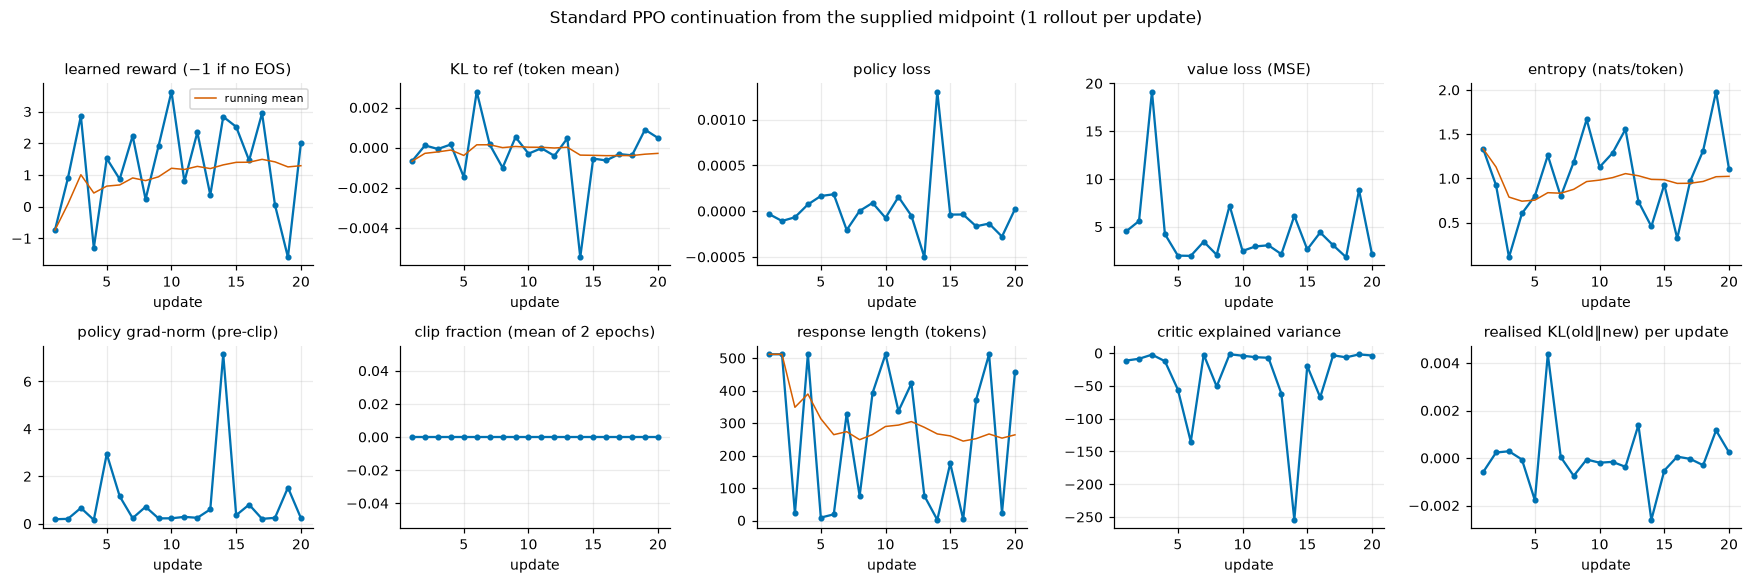

,update,reward,reward_raw,kl_token,kl_seq,policy_loss,value_loss,entropy,grad_norm_policy,clip_fraction,clip_fraction_last_epoch,response_length,truncated,explained_variance,value_mean,return_mean
0,1,-0.7346,0.2654,-0.0007,-0.3462,-0.0000,4.5222,1.3361,0.1909,0.0,0.0,512.0,1.0,-11.3231,-2.2311,-2.1026
1,2,0.9033,1.9033,0.0001,0.0580,-0.0001,5.6079,0.9229,0.2072,0.0,0.0,512.0,1.0,-8.5876,-2.2999,-2.1750
2,3,2.8594,2.8594,-0.0001,-0.0014,-0.0001,19.1409,0.1104,0.6675,0.0,0.0,22.0,0.0,-2.2789,-3.5094,0.4276
3,4,-1.3000,-0.3000,0.0002,0.0818,0.0001,4.2409,0.6045,0.1645,0.0,0.0,512.0,1.0,-12.2405,-2.3466,-2.2895
4,5,1.5225,1.5225,-0.0015,-0.0132,0.0002,1.9873,0.8029,2.9429,0.0,0.0,9.0,0.0,-55.4502,0.1631,1.3150
5,6,0.8687,0.8687,0.0028,0.0531,0.0002,1.9639,1.2602,1.1579,0.0,0.0,19.0,0.0,-135.1875,0.4932,0.6168
6,7,2.2363,2.2363,0.0002,0.0524,-0.0002,3.4493,0.7983,0.2361,0.0,0.0,329.0,0.0,-2.3380,-2.1312,-1.9043
7,8,0.2347,0.2347,-0.0010,-0.0759,0.0000,2.0734,1.1845,0.7153,0.0,0.0,76.0,0.0,-50.7867,0.3196,0.2617
8,9,1.9111,1.9111,0.0005,0.2068,0.0001,7.2250,1.6674,0.2269,0.0,0.0,393.0,0.0,-1.6738,-2.5120,-2.4117
9,10,3.6328,3.6328,-0.0003,-0.1521,-0.0001,2.4808,1.1292,0.2303,0.0,0.0,512.0,0.0,-3.9237,0.1287,0.2594


In [5]:
log = jl(R / "train_log_standard.jsonl")
panels = [("reward", "learned reward (−1 if no EOS)"), ("kl_token", "KL to ref (token mean)"), ("policy_loss", "policy loss"),
          ("value_loss", "value loss (MSE)"), ("entropy", "entropy (nats/token)"), ("grad_norm_policy", "policy grad-norm (pre-clip)"),
          ("clip_fraction", "clip fraction (mean of 2 epochs)"), ("response_length", "response length (tokens)"),
          ("explained_variance", "critic explained variance"), ("post_update_approx_kl", "realised KL(old‖new) per update")]
fig, axes = plt.subplots(2, 5, figsize=(16, 5.2))
for ax, (c, t) in zip(axes.flat, panels):
    ax.plot(log["update"], log[c], "o-", ms=3, color=PALETTE[0])
    if c in ("reward", "kl_token", "response_length", "entropy"):
        ax.plot(log["update"], log[c].expanding().mean(), color=PALETTE[3], lw=1, label="running mean")
    ax.set_title(t); ax.set_xlabel("update")
axes[0, 0].legend(fontsize=7)
fig.suptitle("Standard PPO continuation from the supplied midpoint (1 rollout per update)", y=1.01)
fig.tight_layout(); savefig(fig, "t2_standard_trajectories"); plt.show()
display(log[["update", "reward", "reward_raw", "kl_token", "kl_seq", "policy_loss", "value_loss", "entropy", "grad_norm_policy",
             "clip_fraction", "clip_fraction_last_epoch", "response_length", "truncated", "explained_variance", "value_mean", "return_mean"]].round(4))

In [6]:
first, last = log.head(10), log.tail(10)
print("first half vs second half (means):")
display(pd.DataFrame({"updates 1-10": first.mean(numeric_only=True), "updates 11-20": last.mean(numeric_only=True)}).loc[
    ["reward", "kl_token", "entropy", "response_length", "policy_loss", "value_loss", "explained_variance", "clip_fraction", "grad_norm_policy"]])
print("critic: Spearman(value at first token, realised return of the rollout) =",
      round(pd.Series(log.value_at_first_token).corr(pd.Series(log.reward), method="spearman"), 3))

first half vs second half (means):


,updates 1-10,updates 11-20
reward,1.2134e+00,1.3744e+00
kl_token,2.4861e-05,-5.9206e-04
entropy,9.8164e-01,1.0668e+00
response_length,2.8960e+02,2.3810e+02
policy_loss,3.3441e-06,2.8069e-05
value_loss,5.2692e+00,3.7254e+00
explained_variance,-2.8379e+01,-4.3147e+01
clip_fraction,0.0000e+00,0.0000e+00
grad_norm_policy,6.7396e-01,1.1687e+00


critic: Spearman(value at first token, realised return of the rollout) = 0.066


### Held-out evaluation: SFT reference vs supplied midpoint vs standard continuation

In [7]:
run_module("task2_ppo.evaluate", "--config", "configs/ppo.yaml", "--adapter", "outputs/task2_ppo/standard", "--name", "standard",
           skip_if_exists="results/task2_ppo/heldout_standard.json")
run_module("task2_ppo.evaluate", "--config", "configs/ppo.yaml", "--adapter", "none", "--name", "sft",
           skip_if_exists="results/task2_ppo/heldout_sft.json")
run_module("task2_ppo.evaluate", "--config", "configs/ppo.yaml", "--adapter", cfg["paths"]["ppo_midpoint_policy"], "--name", "midpoint",
           skip_if_exists="results/task2_ppo/heldout_midpoint.json")
def hrow(n):
    s = js(R / f"heldout_{n}.json")
    return {"policy": n, "RM reward": s["reward_mean"], "reward (−1 if no EOS)": s["effective_reward_mean"], "KL token-mean": s["kl_token_mean"],
            "KL per-seq": s["kl_seq_mean"], "entropy": s["entropy_token_mean"], "len mean": s["length"]["mean"], "len std": s["length"]["std"],
            "len IQR": s["length"]["iqr"], "truncation rate (768)": s["truncation_rate"], "n prompts": s["n_prompts"]}
held = pd.DataFrame([hrow(n) for n in ["sft", "midpoint", "standard"]]).set_index("policy")
display(held)

[skip] task2_ppo.evaluate --config configs/ppo.yaml --adapter outputs/task2_ppo/standard --name standard  (found results/task2_ppo/heldout_standard.json)


[skip] task2_ppo.evaluate --config configs/ppo.yaml --adapter none --name sft  (found results/task2_ppo/heldout_sft.json)


[skip] task2_ppo.evaluate --config configs/ppo.yaml --adapter checkpoints/ppo_midpoint_policy --name midpoint  (found results/task2_ppo/heldout_midpoint.json)


,RM reward,reward (−1 if no EOS),KL token-mean,KL per-seq,entropy,len mean,len std,len IQR,truncation rate (768),n prompts
policy,,,,,,,,,,
sft,1.9050,1.8262,0.0000e+00,0.0000,0.9769,309.5030,262.6667,482.0,0.0788,165
midpoint,1.8946,1.8098,2.8647e-05,0.0088,0.9820,308.8788,264.3519,455.0,0.0848,165
standard,1.9040,1.8070,1.9899e-05,0.0062,0.9749,313.6606,269.1124,472.0,0.0970,165


## 4. Clipping study
**(a) Cached-rollout geometry.** The supplied cache holds 32 rollouts with the behaviour policy's
log-probs, reference log-probs and critic values. We rebuild the token sequences exactly as the release
`batch_generate` did (including its right-truncation of prompts longer than 256 tokens — 3 of the 32),
recompute advantages with KL-shaped rewards (β_KL = 0.1) and GAE, and compare the supplied midpoint's
log-probs with the cached ones. *Clip fraction* = share of valid tokens with ρ outside [1−ε, 1+ε];
*affected-token fraction* = share where the min actually selects the clipped constant (ρ>1+ε with A>0 or
ρ<1−ε with A<0), i.e. tokens whose gradient is zeroed.

**(b) Replay.** From the identical midpoint weights we run the release update (2 epochs × minibatches of 4
rollouts, lr 3e-6) on this fixed batch for each ε and track the geometry before every optimizer step.

**(c) Matched forks.** 8-update continuations from the same checkpoint with identical prompts, sampling
seeds, reward and β_KL; only ε changes. The ε = 0.20 fork is the reference setting (shared with the KL study).

In [8]:
run_module("task2_ppo.analyze_clipping", "--config", "configs/ppo.yaml")
rec = jl(R / "clipping_cached_reconstruction.jsonl")
print("reconstruction fidelity (|log π_midpoint − cached old log-prob| per rollout):")
display(rec.describe().T[["mean", "50%", "max"]].round(4))
static = pd.read_csv(R / "clipping_cached_static.csv")
after = pd.read_csv(R / "clipping_cached_after_replay.csv")
display(Markdown("**(a) static geometry: supplied midpoint vs cached behaviour policy**")); display(static.round(5))
display(Markdown("**(b) after replaying the PPO update on the cached batch (16 optimizer steps)**")); display(after.round(5))

[run] python -m task2_ppo.analyze_clipping --config configs/ppo.yaml


Cached PPO rollouts: 32


Required epsilon values: [0.05, 0.2, 0.5]


Cache keys: ['clipped_at_max', 'effective_terminal_reward', 'old_logprobs', 'prompt_id', 'raw_terminal_reward', 'ref_logprobs', 'response', 'response_tokens', 'source_index', 'terminated_with_eos', 'values']


[skip] task2_ppo.evaluate --config configs/ppo.yaml --adapter checkpoints/ppo_midpoint_policy --name midpoint  (found results/task2_ppo/heldout_midpoint.json)


...

,mean,50%,max
source_index,581.1250,567.0000,981.0000
prompt_len,107.7812,94.5000,256.0000
cached_tokens,275.4375,292.5000,512.0000
retokenized_tokens,275.4375,292.5000,512.0000
mean_abs_logp_diff,0.0226,0.0171,0.1738
max_abs_logp_diff,0.2663,0.1575,3.6522


**(a) static geometry: supplied midpoint vs cached behaviour policy**

,eps,clip_fraction,affected_token_fraction,clip_fraction_adv_pos,clip_fraction_adv_neg,clipped_surrogate,unclipped_surrogate,surrogate_gap,ratio_p01,ratio_p99,mean_abs_log_ratio,approx_kl_old_new,n_valid_tokens
0,0.05,0.1061,0.0523,0.1081,0.1040,-0.0053,0.0001,0.0055,0.8957,1.1127,0.0257,0.0001,8814
1,0.20,0.0083,0.0045,0.0080,0.0086,-0.0039,0.0001,0.0041,0.8957,1.1127,0.0257,0.0001,8814
2,0.50,0.0056,0.0033,0.0048,0.0063,-0.0033,0.0001,0.0034,0.8957,1.1127,0.0257,0.0001,8814


**(b) after replaying the PPO update on the cached batch (16 optimizer steps)**

,eps,clip_fraction,affected_token_fraction,clip_fraction_adv_pos,clip_fraction_adv_neg,clipped_surrogate,unclipped_surrogate,surrogate_gap,ratio_p01,ratio_p99,mean_abs_log_ratio,approx_kl_old_new,n_valid_tokens
0,0.05,0.1070,0.0526,0.1061,0.1079,-0.0052,0.0003,0.0055,0.8970,1.1122,0.0257,3.0000e-05,8814
1,0.20,0.0085,0.0046,0.0082,0.0088,-0.0038,0.0003,0.0041,0.8964,1.1142,0.0258,-0.0000e+00,8814
2,0.50,0.0056,0.0033,0.0048,0.0063,-0.0031,0.0003,0.0034,0.8951,1.1157,0.0257,4.0000e-05,8814


saved figure: report/figures/t2_clipping_replay.pdf


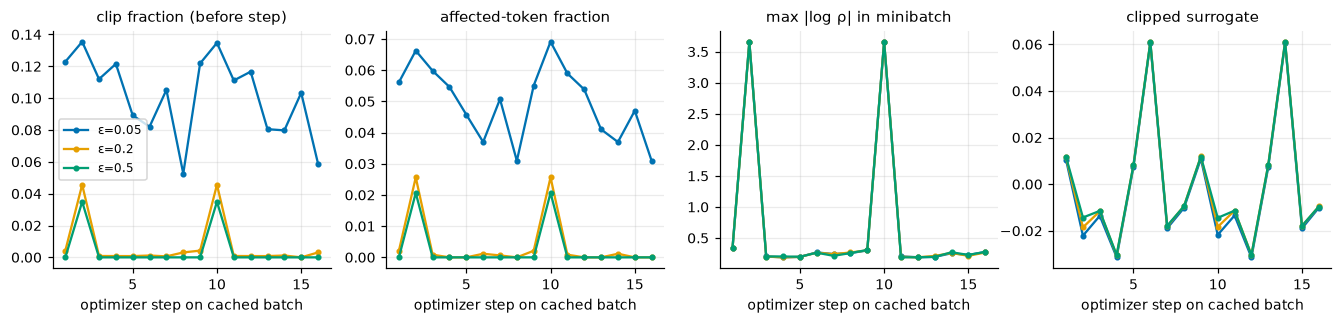

In [9]:
rl = jl(R / "clipping_cached_replay_log.jsonl")
fig, axes = plt.subplots(1, 4, figsize=(15, 2.8))
for i, (e, g) in enumerate(rl.groupby("eps")):
    for ax, c, t in zip(axes, ["clip_fraction", "affected_token_fraction", "max_abs_log_ratio", "clipped_surrogate"],
                        ["clip fraction (before step)", "affected-token fraction", "max |log ρ| in minibatch", "clipped surrogate"]):
        ax.plot(g.step, g[c], "o-", ms=3, label=f"ε={e}", color=PALETTE[i]); ax.set_title(t); ax.set_xlabel("optimizer step on cached batch")
axes[0].legend()
savefig(fig, "t2_clipping_replay"); plt.show()

eps,0.05,0.20,0.50
fork,fork_eps0.05_kl0.10,fork_eps0.20_kl0.10,fork_eps0.50_kl0.10
cached_clip_fraction,0.1061,0.0083,0.0056
cached_affected_token_fraction,0.0523,0.0045,0.0033
cached_clipped_surrogate,-0.0053,-0.0039,-0.0033
replay_clip_fraction_final,0.107,0.0085,0.0056
replay_affected_fraction_final,0.0526,0.0047,0.0033
replay_approx_kl_final,0.0,-0.0,0.0
heldout_reward,1.9032,1.8464,1.8582
heldout_reward_effective,1.8183,1.7494,1.737
heldout_kl_token,-0.0,0.0,0.0


saved figure: report/figures/t2_clipping_forks.pdf


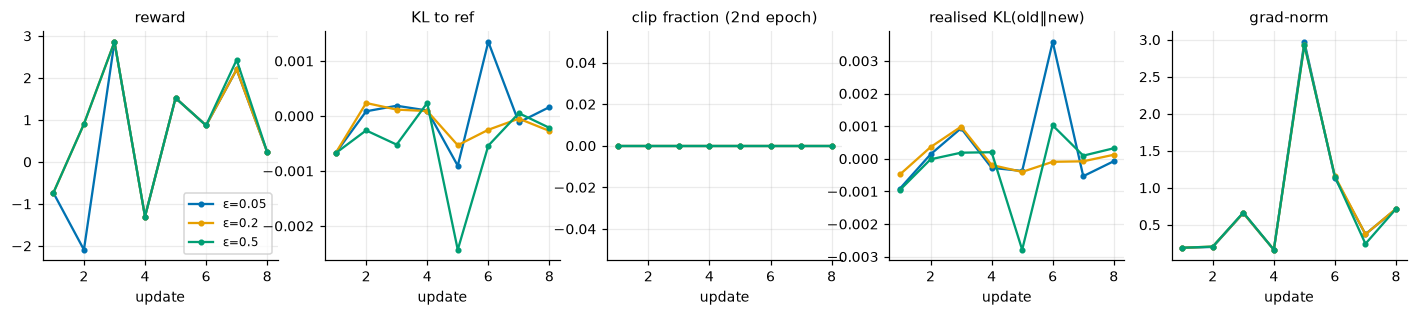

In [10]:
ct = pd.read_csv(R / "clipping_study_table.csv").set_index("eps")
display(ct.T)
fig, axes = plt.subplots(1, 5, figsize=(16, 2.7))
for i, e in enumerate(ct.index):
    d = jl(R / f"train_log_{ct.loc[e, 'fork']}.jsonl")
    for ax, c, t in zip(axes, ["reward", "kl_token", "clip_fraction_last_epoch", "post_update_approx_kl", "grad_norm_policy"],
                        ["reward", "KL to ref", "clip fraction (2nd epoch)", "realised KL(old‖new)", "grad-norm"]):
        ax.plot(d["update"], d[c], "o-", ms=3, label=f"ε={e}", color=PALETTE[i]); ax.set_title(t); ax.set_xlabel("update")
axes[0].legend(); savefig(fig, "t2_clipping_forks"); plt.show()

## 5. KL-pressure (reward over-optimisation) study: β_KL ∈ {0, 0.10, 0.20}

[run] python -m task2_ppo.ablate_kl --config configs/ppo.yaml


KL beta conditions: [0.0, 0.1, 0.2]


Fork update budget: 8


[skip] task2_ppo.evaluate --config configs/ppo.yaml --adapter checkpoints/ppo_midpoint_policy --name midpoint  (found results/task2_ppo/heldout_midpoint.json)


[skip] task2_ppo.continue_train --config configs/ppo.yaml --output outputs/task2_ppo/fork_eps0.20_kl0.00 --updates 8 --clip-epsilon 0.2 --kl-beta 0.0 --run-name fork_eps0.20_kl0.00  (found outputs/task2_ppo/fork_eps0.20_kl0.00/adapter_model.safetensors)


...

train_reward_mean                               0.686234             0.819382             1.284622


train_kl_token_last                              0.00057            -0.000271             0.000144


train_generated_tokens                            2014.0               1971.0               1947.0


kl_beta,0.0,0.1,0.2
fork,fork_eps0.20_kl0.00,fork_eps0.20_kl0.10,fork_eps0.20_kl0.20
heldout_reward,1.909,1.8464,1.8258
heldout_reward_effective,1.8302,1.7494,1.747
heldout_kl_token,0.0,0.0,-0.0
heldout_kl_seq,0.0133,0.0007,-0.0
heldout_entropy,0.9818,0.9901,0.9717
heldout_len_mean,308.5636,311.8606,312.0545
heldout_len_std,263.6638,265.2683,265.36
heldout_len_iqr,455.0,472.0,475.0
heldout_truncation_rate,0.0788,0.097,0.0788


saved figure: report/figures/t2_kl_forks.pdf


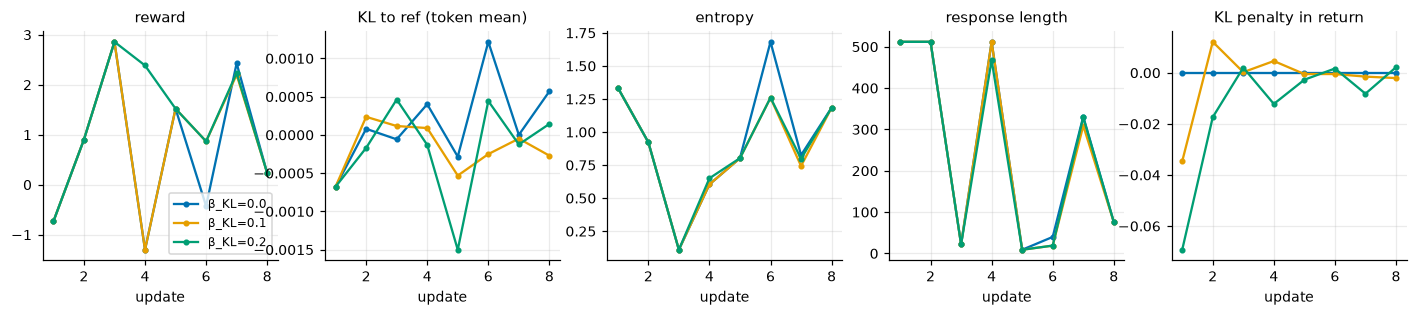

saved figure: report/figures/t2_kl_heldout.pdf


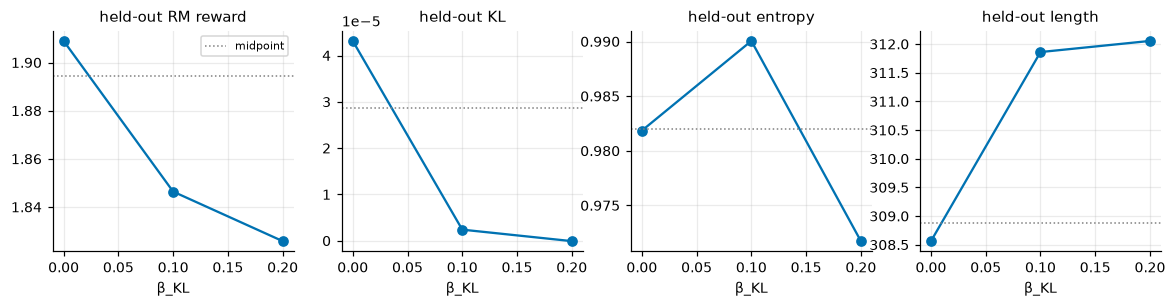

In [11]:
run_module("task2_ppo.ablate_kl", "--config", "configs/ppo.yaml")
kt = pd.read_csv(R / "kl_study_table.csv").set_index("kl_beta")
display(kt.T)
fig, axes = plt.subplots(1, 5, figsize=(16, 2.7))
for i, b in enumerate(kt.index):
    d = jl(R / f"train_log_{kt.loc[b, 'fork']}.jsonl")
    for ax, c, t in zip(axes, ["reward", "kl_token", "entropy", "response_length", "kl_penalty_total"],
                        ["reward", "KL to ref (token mean)", "entropy", "response length", "KL penalty in return"]):
        ax.plot(d["update"], d[c], "o-", ms=3, label=f"β_KL={b}", color=PALETTE[i]); ax.set_title(t); ax.set_xlabel("update")
axes[0].legend(); savefig(fig, "t2_kl_forks"); plt.show()
fig, axes = plt.subplots(1, 4, figsize=(13, 2.6))
for ax, c, t in zip(axes, ["heldout_reward", "heldout_kl_token", "heldout_entropy", "heldout_len_mean"], ["held-out RM reward", "held-out KL", "held-out entropy", "held-out length"]):
    ax.plot(kt.index, kt[c], "o-", color=PALETTE[0]); ax.set_title(t); ax.set_xlabel("β_KL")
    mid = js(R / "heldout_midpoint.json")
    ref = {"heldout_reward": mid["reward_mean"], "heldout_kl_token": mid["kl_token_mean"], "heldout_entropy": mid["entropy_token_mean"], "heldout_len_mean": mid["length"]["mean"]}[c]
    ax.axhline(ref, color="grey", ls=":", lw=1, label="midpoint")
axes[0].legend(fontsize=7); savefig(fig, "t2_kl_heldout"); plt.show()

Which observable moves first when KL pressure is removed? Per-update differences between the β_KL = 0
fork and the β_KL = 0.10 reference fork (same prompts and sampling seeds, so update k sees the same prompt):

In [12]:
d0, d1 = jl(R / f"train_log_{kt.loc[0.0, 'fork']}.jsonl").set_index("update"), jl(R / f"train_log_{kt.loc[0.1, 'fork']}.jsonl").set_index("update")
display((d0[["reward", "kl_token", "kl_seq", "entropy", "response_length", "post_update_approx_kl"]] -
         d1[["reward", "kl_token", "kl_seq", "entropy", "response_length", "post_update_approx_kl"]]).round(4).rename(columns=lambda c: f"Δ {c}"))

,Δ reward,Δ kl_token,Δ kl_seq,Δ entropy,Δ response_length,Δ post_update_approx_kl
update,,,,,,
1,0.0000,0.0000,0.0000,0.0000,0.0,-0.0002
2,0.0000,-0.0002,-0.0802,0.0002,0.0,-0.0002
3,0.0000,-0.0002,-0.0038,0.0001,0.0,-0.0002
4,0.0000,0.0003,0.1595,-0.0002,0.0,0.0004
5,0.0000,0.0002,0.0022,0.0008,0.0,0.0009
6,-1.2937,0.0015,0.0534,0.4229,21.0,0.0009
7,0.2285,0.0000,0.0151,0.0822,22.0,0.0004
8,0.0000,0.0008,0.0639,0.0000,0.0,0.0004


## 6. Qualitative evidence: does reward track quality?
Same held-out prompt, responses from the supplied midpoint and from the β_KL = 0 fork (largest reward
changes in both directions), plus the standard continuation.

In [13]:
def pair(a, b):
    A, B = jl(R / f"heldout_{a}.jsonl").set_index("prompt_id"), jl(R / f"heldout_{b}.jsonl").set_index("prompt_id")
    j = A.join(B, lsuffix=f"_{a}", rsuffix=f"_{b}")
    j["dR"] = j[f"reward_{b}"] - j[f"reward_{a}"]
    return j
j = pair("midpoint", kt.loc[0.0, "fork"])
print("Spearman(Δreward, Δlength) across prompts:", round(j.dR.corr(j[f"response_tokens_{kt.loc[0.0, 'fork']}"] - j["response_tokens_midpoint"], method="spearman"), 3))
for title, sub in [("LARGEST REWARD INCREASE", j.sort_values("dR", ascending=False).head(2)), ("LARGEST REWARD DECREASE", j.sort_values("dR").head(2))]:
    print(f"\n######## {title}")
    for pid, r in sub.iterrows():
        b = kt.loc[0.0, "fork"]
        print(f"\nPROMPT: {excerpt(r.prompt_midpoint, 220)}")
        print(f"  midpoint  (R={r.reward_midpoint:.2f}, {r.response_tokens_midpoint} tok, eos={r.terminated_with_eos_midpoint}): {excerpt(r.response_midpoint, 300)}")
        print(f"  β_KL=0    (R={r[f'reward_{b}']:.2f}, {r[f'response_tokens_{b}']} tok, eos={r[f'terminated_with_eos_{b}']}): {excerpt(r[f'response_{b}'], 300)}")

Spearman(Δreward, Δlength) across prompts: -0.118

######## LARGEST REWARD INCREASE

PROMPT: In at least 500 words, provide a comprehensive analysis of how pesticides affect different types of wildlife,
[...] Use reliable sources to support your argument and format your work according to standard academic
conventions.
  midpoint  (R=2.07, 768 tok, eos=False): Pesticides have been widely used in agriculture for decades as a means of controlling pests and protecting
crops from damage. However, these chemicals [...] ns. **Effectiveness**: Physical methods are particularly
useful for small-scale operations and situations where immediate action is needed. They offer
  β_KL=0    (R=3.48, 713 tok, eos=True): Pesticides have been widely used in agriculture for decades as a means of controlling pests and protecting
crops from damage. However, these chemicals [...]  pivotal roles in ensuring our agricultural landscapes
remain productive and ecologically sound despite ongoing pressures from moder

## 7. Summary tables for the report

In [14]:
display(Markdown("**Standard continuation (20 updates)**"))
display(pd.DataFrame({"mean over 20 updates": log[["reward", "kl_token", "policy_loss", "value_loss", "entropy", "grad_norm_policy", "clip_fraction", "response_length"]].mean(),
                      "last update": log[["reward", "kl_token", "policy_loss", "value_loss", "entropy", "grad_norm_policy", "clip_fraction", "response_length"]].iloc[-1]}).round(4))
display(Markdown("**Clipping study**"))
cols = ["cached_clip_fraction", "cached_affected_token_fraction", "replay_clip_fraction_final", "replay_affected_fraction_final", "heldout_reward", "heldout_kl_token",
        "heldout_len_mean", "heldout_len_std", "stab_mean_post_update_kl", "stab_max_abs_log_ratio", "stab_policy_loss_std", "train_generated_tokens"]
display(ct[cols].round(4))
display(Markdown("**KL-pressure study**"))
display(kt[["heldout_reward", "heldout_kl_token", "heldout_kl_seq", "heldout_entropy", "heldout_len_mean", "heldout_len_std", "train_reward_mean", "train_kl_token_last", "train_generated_tokens"]].round(4))
ct[cols].round(4).to_csv(R / "report_table_task2_clipping.csv"); kt.round(4).to_csv(R / "report_table_task2_kl.csv"); held.round(4).to_csv(R / "report_table_task2_heldout.csv")

**Standard continuation (20 updates)**

,mean over 20 updates,last update
reward,1.2939,2.0020
kl_token,-0.0003,0.0005
policy_loss,0.0000,0.0000
value_loss,4.4973,2.1525
entropy,1.0242,1.1071
grad_norm_policy,0.9213,0.2429
clip_fraction,0.0000,0.0000
response_length,263.8500,456.0000


**Clipping study**

,cached_clip_fraction,cached_affected_token_fraction,replay_clip_fraction_final,replay_affected_fraction_final,heldout_reward,heldout_kl_token,heldout_len_mean,heldout_len_std,stab_mean_post_update_kl,stab_max_abs_log_ratio,stab_policy_loss_std,train_generated_tokens
eps,,,,,,,,,,,,
0.05,0.1061,0.0523,0.1070,0.0526,1.9032,-0.0,304.5939,258.5505,0.0003,0.0305,0.0007,1971.0
0.20,0.0083,0.0045,0.0085,0.0047,1.8464,0.0,311.8606,265.2683,0.0000,0.0420,0.0003,1971.0
0.50,0.0056,0.0033,0.0056,0.0033,1.8582,0.0,311.9576,267.9098,-0.0002,0.0394,0.0005,1993.0


**KL-pressure study**

,heldout_reward,heldout_kl_token,heldout_kl_seq,heldout_entropy,heldout_len_mean,heldout_len_std,train_reward_mean,train_kl_token_last,train_generated_tokens
kl_beta,,,,,,,,,
0.0,1.9090,0.0,0.0133,0.9818,308.5636,263.6638,0.6862,0.0006,2014.0
0.1,1.8464,0.0,0.0007,0.9901,311.8606,265.2683,0.8194,-0.0003,1971.0
0.2,1.8258,-0.0,-0.0000,0.9717,312.0545,265.3600,1.2846,0.0001,1947.0
